In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ Libraries Loaded!")

✅ Libraries Loaded!


In [38]:
df = pd.read_csv('retail_sales_dataset.csv')

print("✅ Dataset Loaded!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

✅ Dataset Loaded!
Shape: (1000, 9)

First 5 rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [39]:
print("=== DATASET INFO ===")
print(df.info())

print("\n=== COLUMN NAMES ===")
print(df.columns.tolist())

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== DUPLICATES ===")
print("Duplicate rows:", df.duplicated().sum())

=== DATASET INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
None

=== COLUMN NAMES ===
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

=== MISSING VALUES ===
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity 

In [40]:
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Extract Month and Year
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year
df['Month_Name'] = df['Date'].dt.strftime('%B')

print("✅ Data Cleaned!")
print(df.head())

✅ Data Cleaned!
   Transaction ID       Date Customer ID  Gender  Age Product Category  \
0               1 2023-11-24     CUST001    Male   34           Beauty   
1               2 2023-02-27     CUST002  Female   26         Clothing   
2               3 2023-01-13     CUST003    Male   50      Electronics   
3               4 2023-05-21     CUST004    Male   37         Clothing   
4               5 2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  Month  Year Month_Name  
0         3              50           150     11  2023   November  
1         2             500          1000      2  2023   February  
2         1              30            30      1  2023    January  
3         1             500           500      5  2023        May  
4         2              50           100      5  2023        May  


In [41]:
print("=== BASIC STATISTICS ===")
print(df.describe())

print("\n=== SALES STATISTICS ===")
print("Mean Sales:  ₹", round(df['Total Amount'].mean(), 2))
print("Median Sales: ₹", round(df['Total Amount'].median(), 2))
print("Mode Sales:  ₹", df['Total Amount'].mode()[0])
print("Std Dev:     ₹", round(df['Total Amount'].std(), 2))
print("Max Sales:   ₹", df['Total Amount'].max())
print("Min Sales:   ₹", df['Total Amount'].min())
print("Total Revenue: ₹", df['Total Amount'].sum())

=== BASIC STATISTICS ===
       Transaction ID                           Date         Age     Quantity  \
count     1000.000000                           1000  1000.00000  1000.000000   
mean       500.500000  2023-07-03 00:25:55.200000256    41.39200     2.514000   
min          1.000000            2023-01-01 00:00:00    18.00000     1.000000   
25%        250.750000            2023-04-08 00:00:00    29.00000     1.000000   
50%        500.500000            2023-06-29 12:00:00    42.00000     3.000000   
75%        750.250000            2023-10-04 00:00:00    53.00000     4.000000   
max       1000.000000            2024-01-01 00:00:00    64.00000     4.000000   
std        288.819436                            NaN    13.68143     1.132734   

       Price per Unit  Total Amount        Month         Year  
count     1000.000000   1000.000000  1000.000000  1000.000000  
mean       179.890000    456.000000     6.549000  2023.002000  
min         25.000000     25.000000     1.000000  202

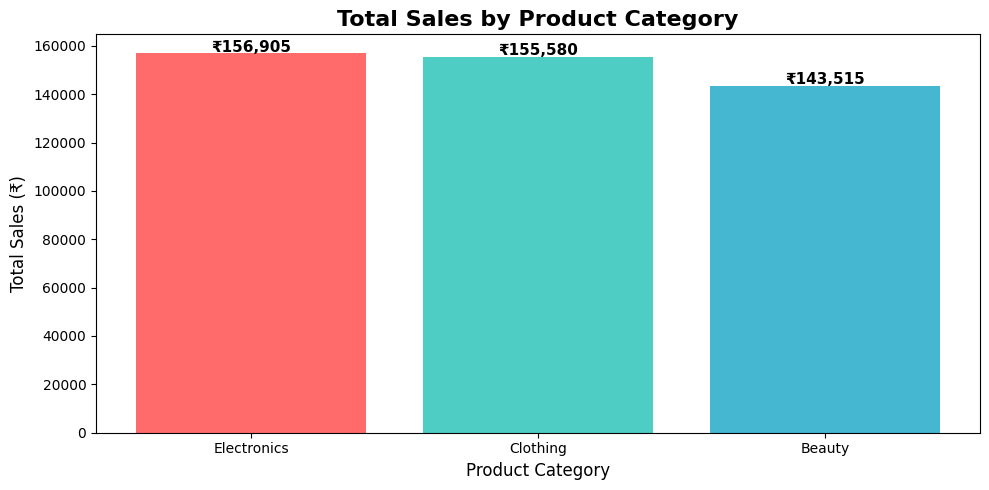

✅ Chart 1 Saved!


In [42]:
plt.figure(figsize=(10,5))
category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)
bars = plt.bar(category_sales.index, category_sales.values, color=['#FF6B6B','#4ECDC4','#45B7D1'])
plt.title('Total Sales by Product Category', fontsize=16, fontweight='bold')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Sales (₹)', fontsize=12)
for bar, val in zip(bars, category_sales.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
             f'₹{val:,}', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('chart1_category_sales.png', dpi=150)
plt.show()
print("✅ Chart 1 Saved!")

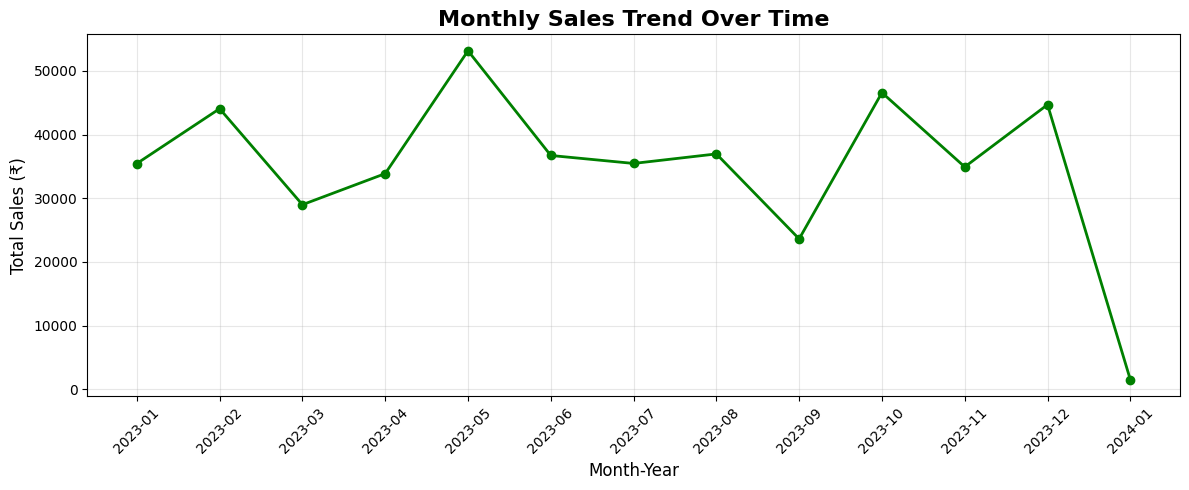

✅ Chart 2 Saved!


In [43]:
plt.figure(figsize=(12,5))
monthly_sales = df.groupby(['Year','Month'])['Total Amount'].sum().reset_index()
monthly_sales['Period'] = monthly_sales['Year'].astype(str) + '-' + monthly_sales['Month'].astype(str).str.zfill(2)
plt.plot(monthly_sales['Period'], monthly_sales['Total Amount'],
         marker='o', color='green', linewidth=2, markersize=6)
plt.title('Monthly Sales Trend Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Month-Year', fontsize=12)
plt.ylabel('Total Sales (₹)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('chart2_sales_trend.png', dpi=150)
plt.show()
print("✅ Chart 2 Saved!")

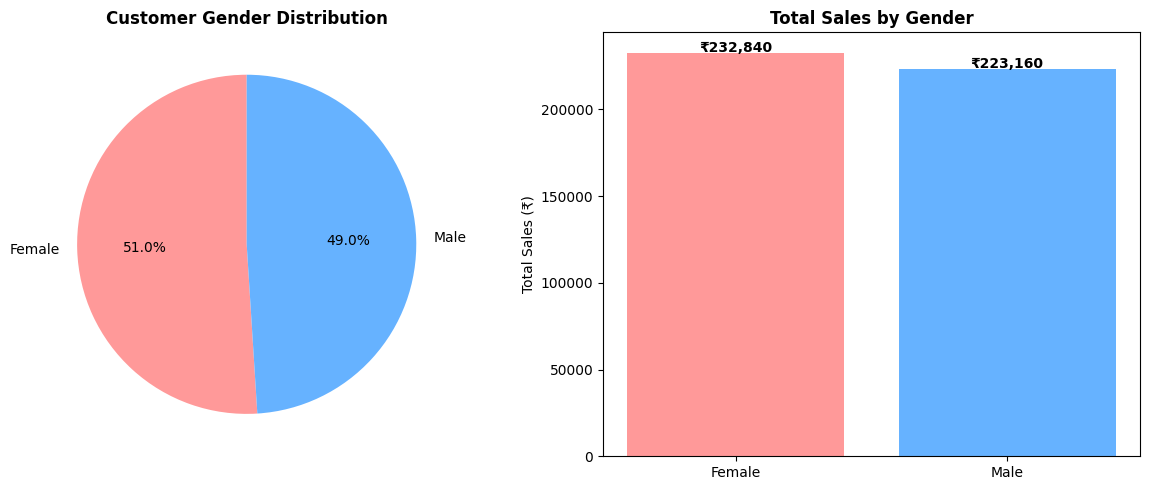

✅ Chart 3 Saved!


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Gender Count
gender_count = df['Gender'].value_counts()
axes[0].pie(gender_count.values, labels=gender_count.index,
            autopct='%1.1f%%', colors=['#FF9999','#66B2FF'], startangle=90)
axes[0].set_title('Customer Gender Distribution', fontweight='bold')

# Gender vs Sales
gender_sales = df.groupby('Gender')['Total Amount'].sum()
axes[1].bar(gender_sales.index, gender_sales.values, color=['#FF9999','#66B2FF'])
axes[1].set_title('Total Sales by Gender', fontweight='bold')
axes[1].set_ylabel('Total Sales (₹)')
for i, (idx, val) in enumerate(gender_sales.items()):
    axes[1].text(i, val + 500, f'₹{val:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('chart3_gender_analysis.png', dpi=150)
plt.show()
print("✅ Chart 3 Saved!")

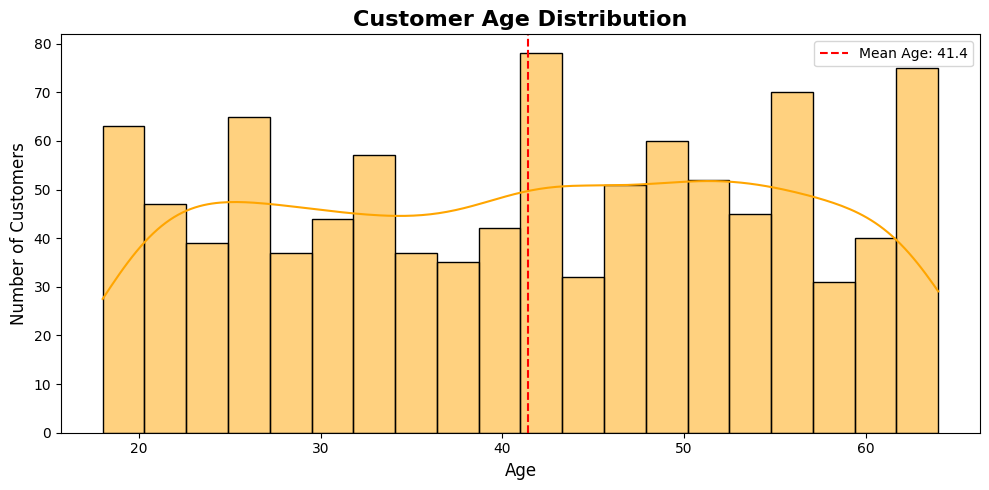

✅ Chart 4 Saved!


In [45]:
plt.figure(figsize=(10,5))
sns.histplot(df['Age'], bins=20, color='orange', kde=True)
plt.title('Customer Age Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.axvline(df['Age'].mean(), color='red', linestyle='--',
            label=f'Mean Age: {df["Age"].mean():.1f}')
plt.legend()
plt.tight_layout()
plt.savefig('chart4_age_distribution.png', dpi=150)
plt.show()
print("✅ Chart 4 Saved!")

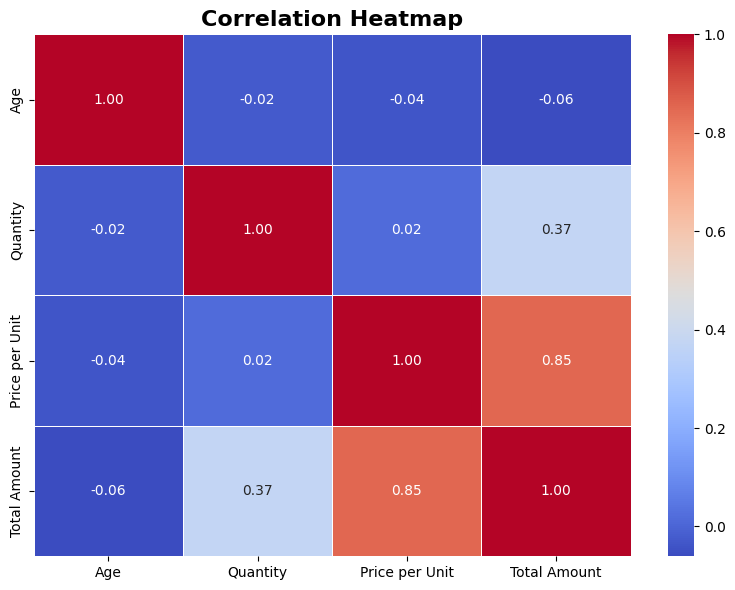

✅ Chart 5 Saved!


In [46]:
plt.figure(figsize=(8,6))
numeric_df = df[['Age','Quantity','Price per Unit','Total Amount']]
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('chart5_heatmap.png', dpi=150)
plt.show()
print("✅ Chart 5 Saved!")

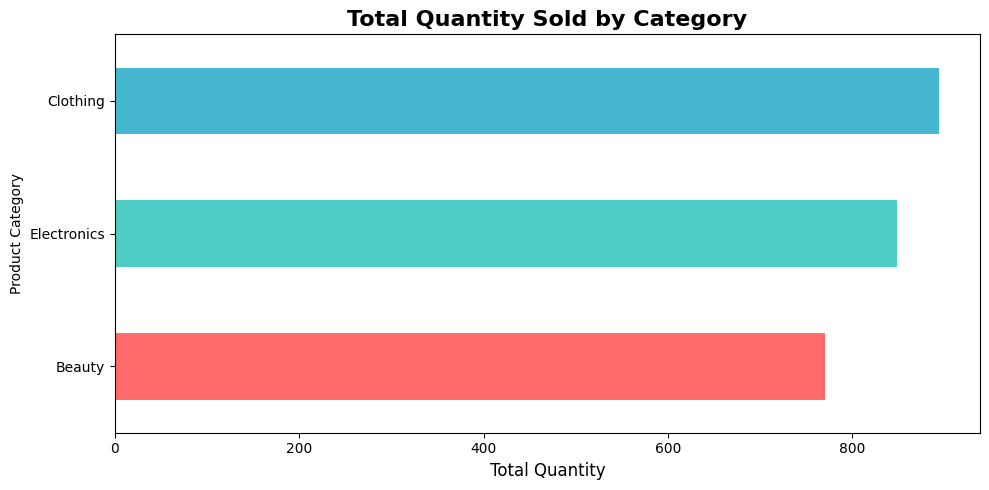

✅ Chart 6 Saved!


In [47]:
plt.figure(figsize=(10,5))
qty_by_category = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=True)
qty_by_category.plot(kind='barh', color=['#FF6B6B','#4ECDC4','#45B7D1'])
plt.title('Total Quantity Sold by Category', fontsize=16, fontweight='bold')
plt.xlabel('Total Quantity', fontsize=12)
plt.tight_layout()
plt.savefig('chart6_quantity.png', dpi=150)
plt.show()
print("✅ Chart 6 Saved!")

In [48]:
print("=" * 50)
print("📊 KEY INSIGHTS & RECOMMENDATIONS")
print("=" * 50)

top_cat = df.groupby('Product Category')['Total Amount'].sum().idxmax()
top_gender = df.groupby('Gender')['Total Amount'].sum().idxmax()
avg_age = round(df['Age'].mean(), 1)
total_rev = df['Total Amount'].sum()
best_month = df.groupby('Month')['Total Amount'].sum().idxmax()

print(f"\n1. 💰 Total Revenue Generated: ₹{total_rev:,}")
print(f"2. 🏆 Top Selling Category: {top_cat}")
print(f"3. 👤 Higher Spending Gender: {top_gender}")
print(f"4. 🎂 Average Customer Age: {avg_age} years")
print(f"5. 📅 Best Sales Month: Month {best_month}")
print("\n📌 RECOMMENDATIONS:")
print(f"   → Focus marketing on {top_cat} category")
print(f"   → Target age group 25-45 for promotions")
print(f"   → Boost stock before Month {best_month} (peak season)")
print(f"   → Create gender-specific offers for {top_gender} customers")

📊 KEY INSIGHTS & RECOMMENDATIONS

1. 💰 Total Revenue Generated: ₹456,000
2. 🏆 Top Selling Category: Electronics
3. 👤 Higher Spending Gender: Female
4. 🎂 Average Customer Age: 41.4 years
5. 📅 Best Sales Month: Month 5

📌 RECOMMENDATIONS:
   → Focus marketing on Electronics category
   → Target age group 25-45 for promotions
   → Boost stock before Month 5 (peak season)
   → Create gender-specific offers for Female customers
